<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter5/angle_deception.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Euler-Cromer and Velocity Verlet descent time from rest compared.

<>:203: SyntaxWarning: invalid escape sequence '\s'
<>:204: SyntaxWarning: invalid escape sequence '\s'
<>:203: SyntaxWarning: invalid escape sequence '\s'
<>:204: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_4821/1642388761.py:203: SyntaxWarning: invalid escape sequence '\s'
  f"Verlet error is $\sim 10^{-6}$ vs\n"
/tmp/ipykernel_4821/1642388761.py:204: SyntaxWarning: invalid escape sequence '\s'
  f"Cromer error $\sim 10^{-2}$.\n"


--- PENDULUM PARADOX VERIFICATION ---
Release Angle (theta_0): 90.0 degrees

[Analytical] The exact equal-time split should occur at: 65.5302 degrees

[Numerical] Testing the '60.0 degree' Deception:
  - Time for Upper Arc AP (90.0 to 60.0 deg): 0.3290 s
  - Time for Lower Arc PB (60.0 to 0 deg): 0.2630 s
  -> Paradox Confirmed: The shorter Upper Arc AP takes LONGER time!

[Numerical] Isochronous Search:
  - Total Fall Time: 0.5920 s
  - Target Half-Time: 0.2960 s
  - Angle at Half-Time (beta_c): 65.5270 degrees
  - Error vs Analytical: 0.003231 degrees


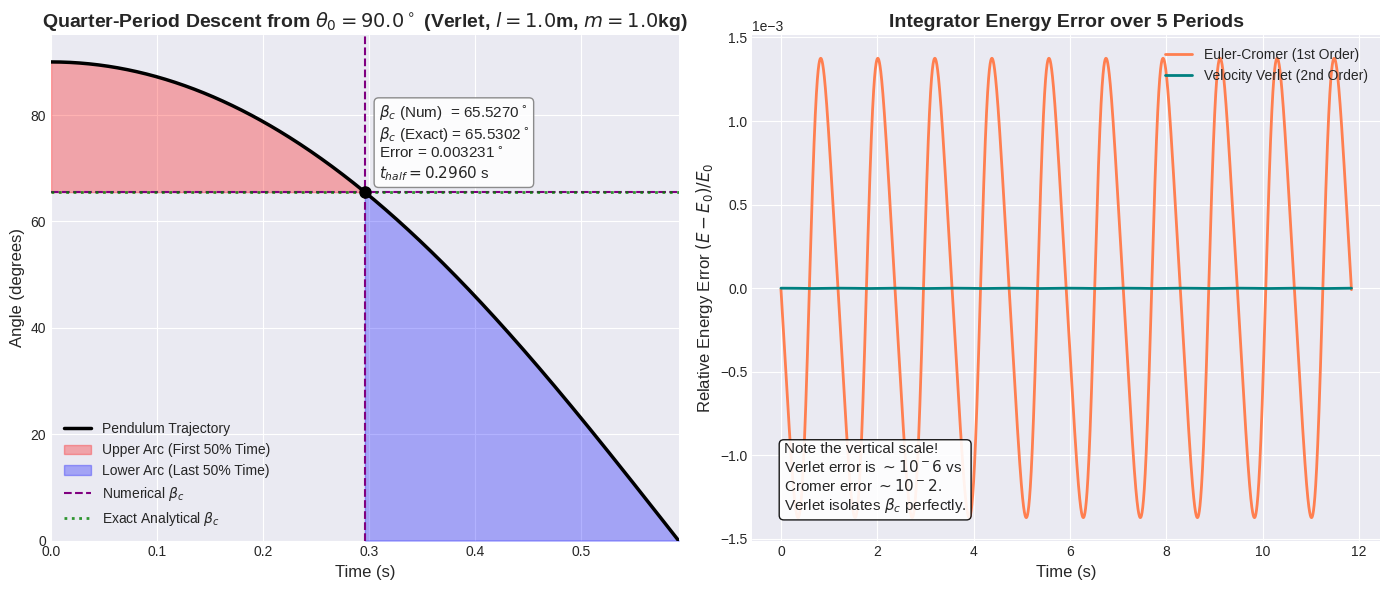

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# --- Physical Constants ---
g = 9.81  # Acceleration due to gravity (m/s^2)
L = 1.0   # Length of the pendulum (m)
m = 1.0   # Mass of the bob (kg)

# --- Simulation Parameters ---
dt = 0.001          # Time step (seconds). Small dt ensures high precision.
theta0_deg = 90.0   # Initial release angle in degrees
beta_test_deg = 60.0 # Intermediate angle for Part (a) paradox test (degrees)

theta0 = np.radians(theta0_deg)
beta_test = np.radians(beta_test_deg)

def calculate_energy(theta, omega):
    """Calculates the total mechanical energy of the pendulum."""
    kinetic = 0.5 * m * (L * omega)**2
    potential = m * g * L * (1 - np.cos(theta))
    return kinetic + potential

def euler_cromer_step(theta, omega, dt):
    """
    Performs one step of the Euler-Cromer (Semi-Implicit Euler) method.
    It updates velocity first, then uses the NEW velocity to update position.
    This makes it symplectic (energy-conserving over the long term).
    """
    acceleration = -(g / L) * np.sin(theta)
    omega_next = omega + acceleration * dt
    theta_next = theta + omega_next * dt
    return theta_next, omega_next

def verlet_step(theta, omega, dt):
    """
    Performs one step of the Velocity Verlet method.
    This is a 2nd-order symplectic integrator, heavily used in molecular
    dynamics for its superior energy conservation and accuracy.
    """
    # 1. Calculate current acceleration
    accel_current = -(g / L) * np.sin(theta)

    # 2. Update position using current velocity and acceleration
    theta_next = theta + omega * dt + 0.5 * accel_current * dt**2

    # 3. Calculate new acceleration at the updated position
    accel_next = -(g / L) * np.sin(theta_next)

    # 4. Update velocity using the average of current and next accelerations
    omega_next = omega + 0.5 * (accel_current + accel_next) * dt

    return theta_next, omega_next

def simulate_quarter_swing(integrator_func, theta_start, target_beta):
    """
    Simulates the pendulum from release until it passes the vertical (0 rad).
    Tracks the time it takes to reach an intermediate target angle (beta).
    """
    t = 0.0
    theta = theta_start
    omega = 0.0

    times = [t]
    thetas = [theta]
    energies = [calculate_energy(theta, omega)]

    t_AP = None  # Time to reach target_beta
    t_bottom = None # Time to reach 0 (bottom)

    # Loop until the pendulum swings past the bottom (theta <= 0)
    while theta > 0:
        theta, omega = integrator_func(theta, omega, dt)
        t += dt

        times.append(t)
        thetas.append(theta)
        energies.append(calculate_energy(theta, omega))

        # Log time when it crosses the intermediate test angle (e.g., 60 deg)
        if t_AP is None and theta <= target_beta:
            t_AP = t

    t_bottom = t

    return np.array(times), np.array(thetas), np.array(energies), t_AP, t_bottom

print(f"--- PENDULUM PARADOX VERIFICATION ---")
print(f"Release Angle (theta_0): {theta0_deg} degrees")

# 1. Analytical Prediction for critical angle beta_c
cos_betac = 2 * np.cos(theta0 / 2) - 1
betac_analytical = np.degrees(np.arccos(cos_betac))
print(f"\n[Analytical] The exact equal-time split should occur at: {betac_analytical:.4f} degrees")

# 2. Run high-precision simulation using Velocity Verlet
times, thetas, energies_verlet, t_AP, t_bottom = simulate_quarter_swing(
    verlet_step, theta0, beta_test
)

t_PB = t_bottom - t_AP
print(f"\n[Numerical] Testing the '{beta_test_deg} degree' Deception:")
print(f"  - Time for Upper Arc AP ({theta0_deg} to {beta_test_deg} deg): {t_AP:.4f} s")
print(f"  - Time for Lower Arc PB ({beta_test_deg} to 0 deg): {t_PB:.4f} s")

if t_AP > t_PB:
    print(f"  -> Paradox Confirmed: The shorter Upper Arc AP takes LONGER time!")
else:
    print(f"  -> The Lower Arc PB takes longer.")

# Find the exact array index where time is half of the total fall time
half_time = t_bottom / 2.0
# Find the closest time index to half_time
half_index = np.abs(times - half_time).argmin()
betac_numerical = np.degrees(thetas[half_index])

print(f"\n[Numerical] Isochronous Search:")
print(f"  - Total Fall Time: {t_bottom:.4f} s")
print(f"  - Target Half-Time: {half_time:.4f} s")
print(f"  - Angle at Half-Time (beta_c): {betac_numerical:.4f} degrees")
print(f"  - Error vs Analytical: {abs(betac_numerical - betac_analytical):.6f} degrees")

# To show energy conservation, we need to run for several periods
periods_to_simulate = 5
t_max = periods_to_simulate * (4 * t_bottom)

def simulate_long(integrator_func, t_max):
    t, theta, omega = 0.0, theta0, 0.0
    energies = []
    times_arr = []

    while t <= t_max:
        theta, omega = integrator_func(theta, omega, dt)
        t += dt
        energies.append(calculate_energy(theta, omega))
        times_arr.append(t)
    return np.array(times_arr), np.array(energies)

times_long, E_cromer = simulate_long(euler_cromer_step, t_max)
_, E_verlet = simulate_long(verlet_step, t_max)
E_exact = calculate_energy(theta0, 0.0)

# --- Plotting ---
plt.style.use('seaborn-v0_8-darkgrid')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Trajectory and the Isochronous Split
thetas_deg = np.degrees(thetas)
ax1.plot(times, thetas_deg, 'k-', linewidth=2.5, label='Pendulum Trajectory')

# Shade the Upper Region (Time 0 to half_time)
ax1.fill_between(times[:half_index+1], thetas_deg[:half_index+1],
                 betac_numerical, color='red', alpha=0.3, label='Upper Arc (First 50% Time)')

# Shade the Lower Region (Time half_time to end)
ax1.fill_between(times[half_index:], thetas_deg[half_index:],
                 0, color='blue', alpha=0.3, label='Lower Arc (Last 50% Time)')

ax1.axhline(betac_numerical, color='purple', linestyle='--', linewidth=1.5, label='Numerical $\\beta_c$')
ax1.axhline(betac_analytical, color='green', linestyle=':', linewidth=2, alpha=0.8, label='Exact Analytical $\\beta_c$')
ax1.axvline(half_time, color='purple', linestyle='--', linewidth=1.5)

ax1.plot(half_time, betac_numerical, 'ko', markersize=8, zorder=5)

error_val = abs(betac_numerical - betac_analytical)
annotation_text = (
    f"$\\beta_c$ (Num)  = {betac_numerical:.4f}$^\\circ$\n"
    f"$\\beta_c$ (Exact) = {betac_analytical:.4f}$^\\circ$\n"
    f"Error = {error_val:.6f}$^\\circ$\n"
    f"$t_{{half}} = {half_time:.4f}$ s"
)
ax1.annotate(annotation_text,
             (half_time, betac_numerical), xytext=(10, 10),
             textcoords='offset points', fontsize=11,
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9))

ax1.set_title(f'Quarter-Period Descent from $\\theta_0 = {theta0_deg}^\\circ$ (Verlet, $l={L}$m, $m={m}$kg)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Time (s)', fontsize=12)
ax1.set_ylabel('Angle (degrees)', fontsize=12)
ax1.set_xlim(0, t_bottom)
ax1.set_ylim(0, theta0_deg + 5)
ax1.legend(loc='lower left')

# Plot 2: Integrator Energy Conservation Comparison
# We plot the relative error: (E(t) - E_exact) / E_exact
err_cromer = (E_cromer - E_exact) / E_exact
err_verlet = (E_verlet - E_exact) / E_exact

ax2.plot(times_long, err_cromer, color='coral', linewidth=2, label='Euler-Cromer (1st Order)')
ax2.plot(times_long, err_verlet, color='teal', linewidth=2, label='Velocity Verlet (2nd Order)')

ax2.set_title(f'Integrator Energy Error over {periods_to_simulate} Periods', fontsize=14, fontweight='bold')
ax2.set_xlabel('Time (s)', fontsize=12)
ax2.set_ylabel('Relative Energy Error $(E - E_0) / E_0$', fontsize=12)

# Format y-axis as scientific notation for clarity
ax2.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
ax2.legend(loc='upper right')

# Add an explanatory text box about why Verlet is used
textstr = (
    f"Note the vertical scale!\n"
    f"Verlet error is $\sim 10^{-6}$ vs\n"
    f"Cromer error $\sim 10^{-2}$.\n"
    f"Verlet isolates $\\beta_c$ perfectly."
)
props = dict(boxstyle='round', facecolor='white', alpha=0.9)
ax2.text(0.05, 0.05, textstr, transform=ax2.transAxes, fontsize=11,
        verticalalignment='bottom', bbox=props)

plt.tight_layout()
plt.show()